In [ ]:
# Environment and path setup is handled in the next cell.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Arquivos disponíveis em utils: ['test_sticks_in_subregions.ipynb', 'PiaNo.ipynb', 'pruning.py', 'utility_reset.py', 'filtered_paths.py', '__pycache__', 'region_checks.py', 'intersection_utils.py', 'point_generator.py', 'path_analysis.py', 'plotting.py', 'nextSteps.txt', 'test_all_subregions.py', 'test_new_data_sctructures.ipynb', 'test_paths_in_subregions.ipynb']


In [ ]:
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
#from predefined_networks import *
from tests import *

# **Executing the Experiment**

In [ ]:
# Variáveis principais
a = 0.70
N = 30

points_1 = []
points_2 = []
angles = []
graph = [] #arestas
nodes = []
intersected_line_1 = []
intersected_line_2 = []
intersections_points = []
all_connected_nodes = []
solutions = []
A = []
L = []
paths = []

In [ ]:
generate_points(N, points_1, points_2, angles, a)

In [ ]:
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(points_1, points_2, intersections_points, intersected_line_1, intersected_line_2, graph, angles, a, N)

In [ ]:
len(intersections_points)

59

In [ ]:
boundary_condition_source = []
boundary_condition_drain = []

In [ ]:
for i in range(len(intersections_points)):
  if intersections_points[i][0] < 0.1:
    boundary_condition_source.append(i)
  elif intersections_points[i][0] > 0.9:
    boundary_condition_drain.append(i)

In [ ]:
print("Number of identified intersection points =", len(intersections_points))
print("In the source contact region =", len(boundary_condition_source))
print("In the drain contact region =", len(boundary_condition_drain))
print(boundary_condition_source)

Number of identified intersection points = 59
In the source contact region = 2
In the drain contact region = 2
[37, 53]


In [ ]:
path_nodes, path_pairs_of_lines, path_pairs_of_edges, all_path_perc = [], [], [], []

In [ ]:
for i in boundary_condition_source:
  do_not_check = 0
  number_path = len(all_connected_nodes)
  for k in range(0,number_path):
    if i in all_connected_nodes[k]:
      do_not_check = 1
  if do_not_check == 0:
    # print(f"Path number = {number_path}")
    # print(f"node = {i}")
    start_node = i
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(intersections_points, graph, start_node)
    path_nodes.append(nodes)
    path_pairs_of_lines.append(pair_of_lines)
    path_pairs_of_edges.append(pair_of_edges,)
    all_path_perc.append(path_perc)
  # print(f"All nodes = {all_connected_nodes}")
  # print(f"All lines = {pair_of_lines}")

valor de queue antes = deque([37])
valor de queue depois = deque([])
nós visitados {37}
valor de target edge = (17, 3)
valor de path_pairs_of_lines = [(17, 3)]
valor do i = 6
valor do current node = 37
valor da queue após append = deque([6])
valor do path_pairs_of_nodes[37, 6]
valor do path_pairs_of_lines = [(17, 3), (1, 3)]
valor do path_pairs_of_edges = [(37, 6)]
valor do i = 19
valor do current node = 37
valor da queue após append = deque([6, 19])
valor do path_pairs_of_nodes[37, 6, 19]
valor do path_pairs_of_lines = [(17, 3), (1, 3), (11, 3)]
valor do path_pairs_of_edges = [(37, 6), (37, 19)]
valor do i = 23
valor do current node = 37
valor da queue após append = deque([6, 19, 23])
valor do path_pairs_of_nodes[37, 6, 19, 23]
valor do path_pairs_of_lines = [(17, 3), (1, 3), (11, 3), (11, 17)]
valor do path_pairs_of_edges = [(37, 6), (37, 19), (37, 23)]
valor do i = 34
valor do current node = 37
valor da queue após append = deque([6, 19, 23, 34])
valor do path_pairs_of_nodes[37, 6, 1

In [ ]:
print(path_nodes) #create list of the correspoding pairs of edges
print(path_pairs_of_lines) #check what it is
print(path_pairs_of_edges) #create list of the correspoding nodes
print(all_path_perc)

[[37, 6, 19, 23, 34, 38, 39, 40, 58, 5, 7, 8, 9, 10, 18, 33, 20, 21, 22, 35, 36, 55, 0, 28, 44, 48, 1, 29, 41, 45, 49, 46, 47, 56, 2, 3, 4, 27, 42, 43, 11, 30, 50, 51, 52, 31, 32, 16, 25, 54, 17, 26, 12, 13, 14, 15, 24, 57, 53], [53, 12, 11, 2, 30, 36, 46, 48, 49, 50, 51, 52, 0, 1, 3, 4, 5, 27, 28, 29, 31, 32, 22, 33, 34, 35, 55, 10, 40, 44, 45, 47, 7, 20, 38, 8, 21, 39, 41, 16, 25, 42, 54, 17, 26, 43, 6, 9, 18, 19, 23, 37, 58, 56, 13, 14, 15, 24, 57]]
[[(17, 3), (1, 3), (11, 3), (11, 17), (16, 3), (17, 7), (17, 8), (17, 19), (28, 3), (1, 0), (1, 7), (1, 8), (1, 18), (1, 19), (11, 1), (16, 1), (11, 7), (11, 8), (11, 16), (16, 19), (16, 20), (26, 16), (0, 7), (15, 7), (19, 7), (20, 7), (0, 8), (15, 8), (18, 8), (19, 8), (20, 8), (19, 20), (19, 22), (26, 28), (0, 20), (0, 22), (0, 24), (15, 0), (18, 22), (18, 24), (2, 20), (15, 20), (20, 22), (20, 24), (20, 25), (15, 22), (15, 24), (9, 22), (14, 22), (24, 22), (9, 24), (14, 24), (2, 23), (9, 6), (9, 10), (9, 14), (14, 12), (27, 14), (21,

# **Tests**

In [ ]:
angles = []

🚀 TESTE COMPLETO - VISUALIZAÇÃO DIRETA: TODAS AS 16 SUBREGIÕES
Plotagem direta usando matplotlib para garantir visibilidade

📍 TESTE 1/16: Região 1 - Subregião 1
----------------------------------------
   Centro: (-0.030, 0.030)
   Paths gerados: 6
   Range X: -0.0658 a 0.0374
   Range Y: -0.0241 a 0.0908
   Interseções detectadas: 2


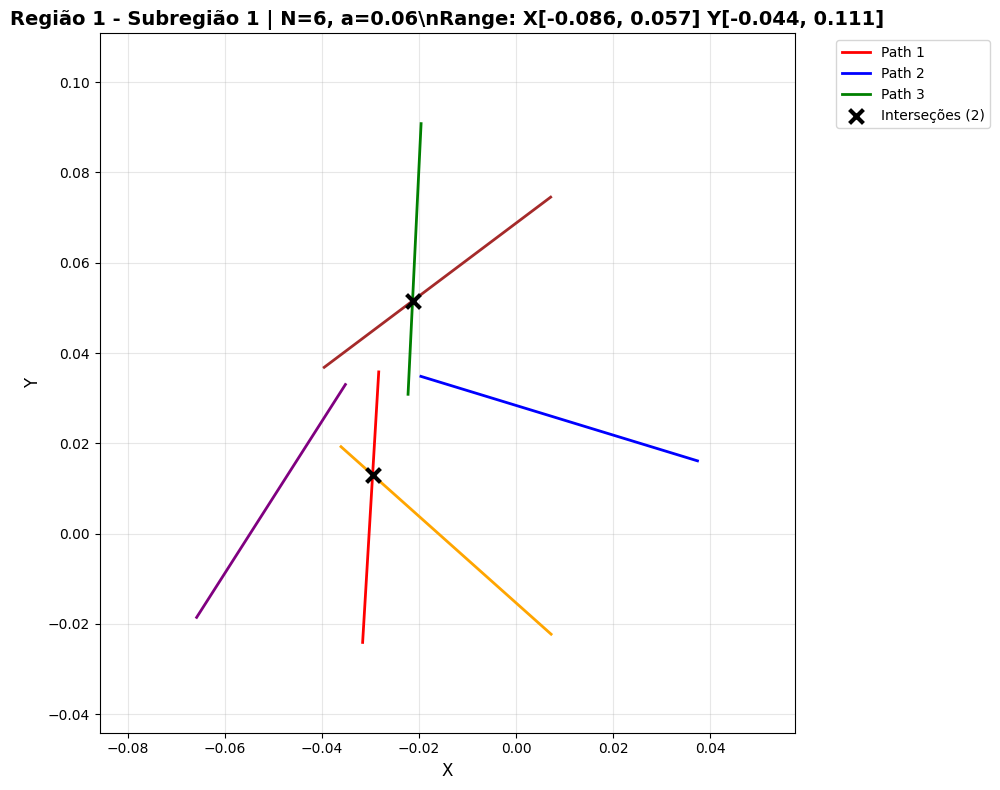

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 2/16: Região 1 - Subregião 2
----------------------------------------
   Centro: (-0.030, -0.030)
   Paths gerados: 6
   Range X: -0.0751 a 0.0333
   Range Y: -0.0745 a 0.0317
   Interseções detectadas: 4


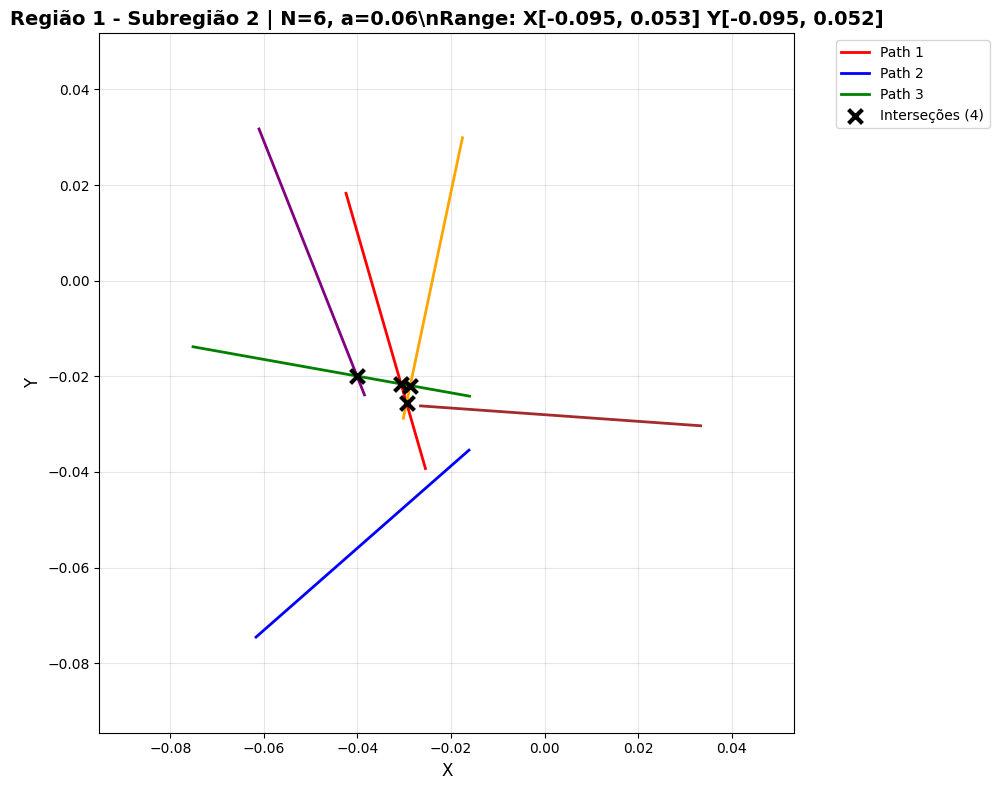

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 3/16: Região 1 - Subregião 3
----------------------------------------
   Centro: (0.030, 0.030)
   Paths gerados: 6
   Range X: -0.0357 a 0.1035
   Range Y: -0.0186 a 0.0980
   Interseções detectadas: 3


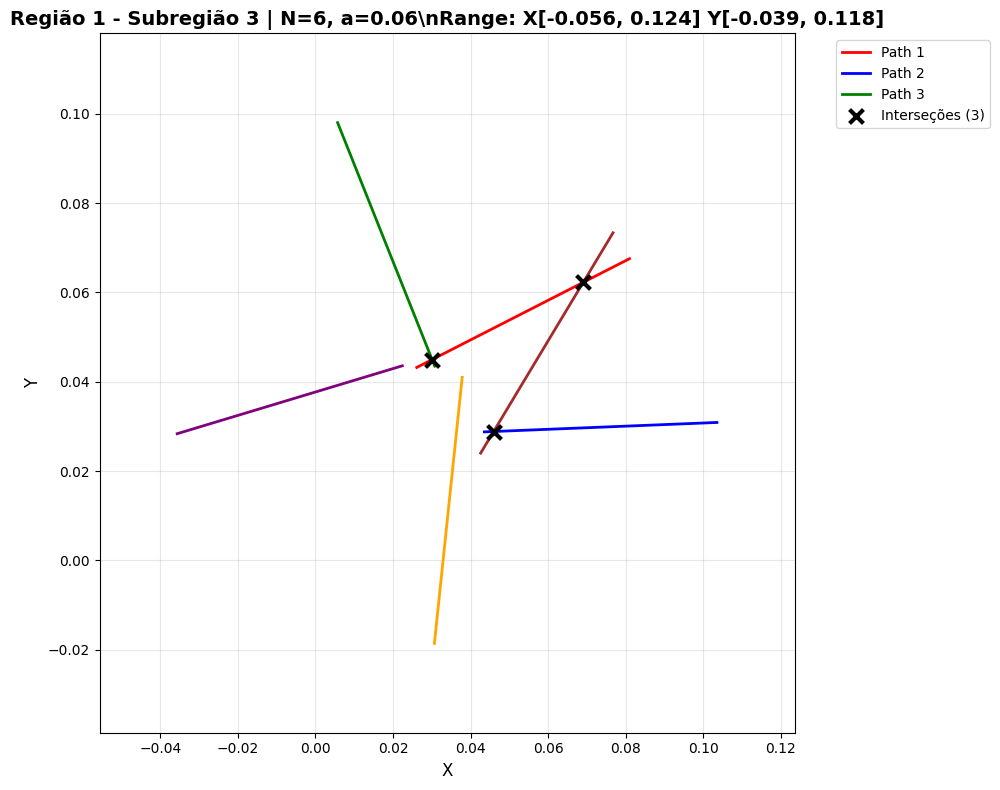

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 4/16: Região 1 - Subregião 4
----------------------------------------
   Centro: (0.030, -0.030)
   Paths gerados: 6
   Range X: -0.0280 a 0.0442
   Range Y: -0.0772 a 0.0360
   Interseções detectadas: 5


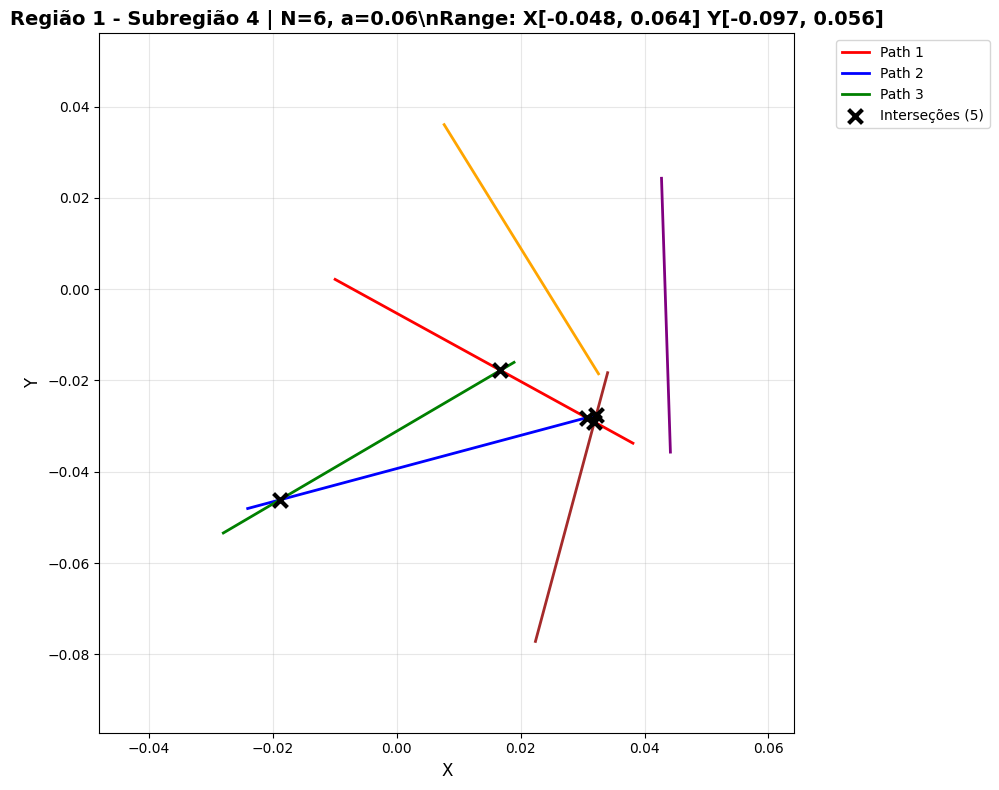

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 5/16: Região 2 - Subregião 1
----------------------------------------
   Centro: (0.080, 0.030)
   Paths gerados: 6
   Range X: 0.0156 a 0.1378
   Range Y: -0.0355 a 0.0921
   Interseções detectadas: 1


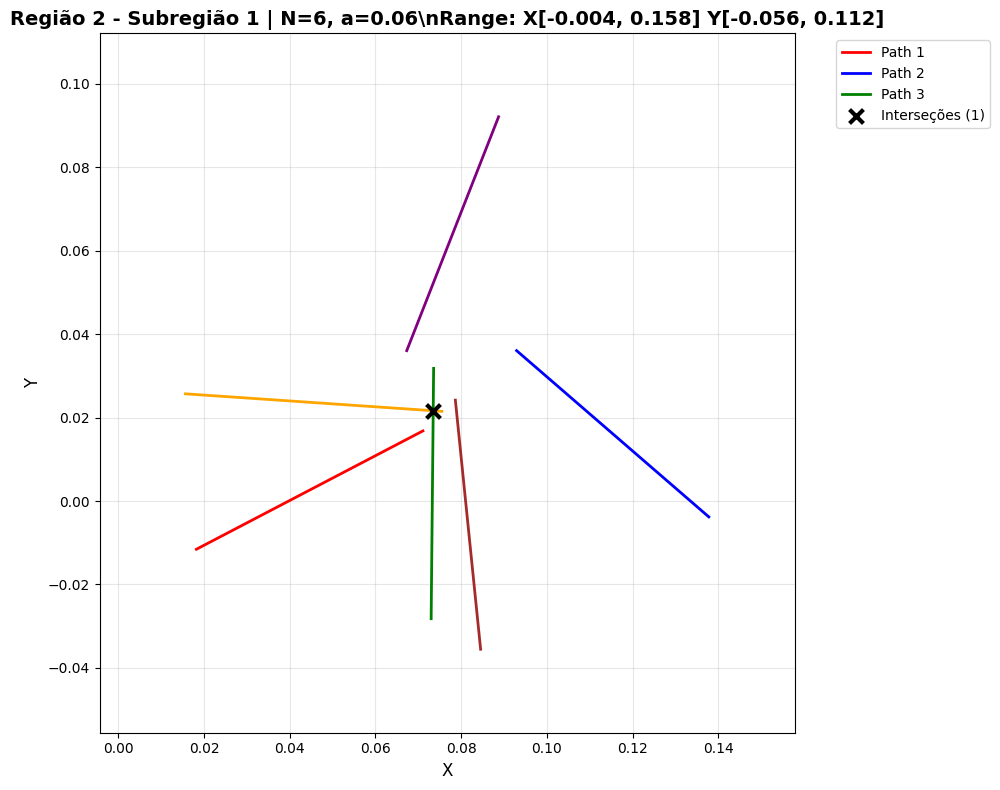

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 6/16: Região 2 - Subregião 2
----------------------------------------
   Centro: (0.080, -0.030)
   Paths gerados: 6
   Range X: 0.0317 a 0.1483
   Range Y: -0.0937 a 0.0044
   Interseções detectadas: 2


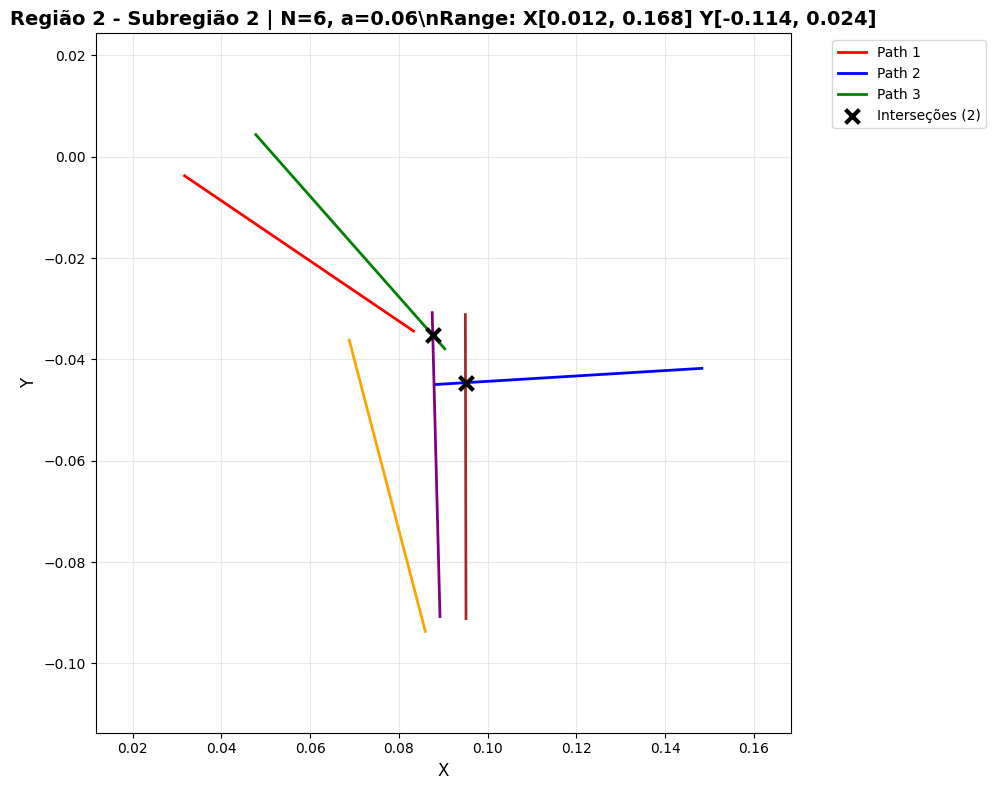

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 7/16: Região 2 - Subregião 3
----------------------------------------
   Centro: (0.110, 0.030)
   Paths gerados: 6
   Range X: 0.0385 a 0.1391
   Range Y: -0.0296 a 0.1016
   Interseções detectadas: 3


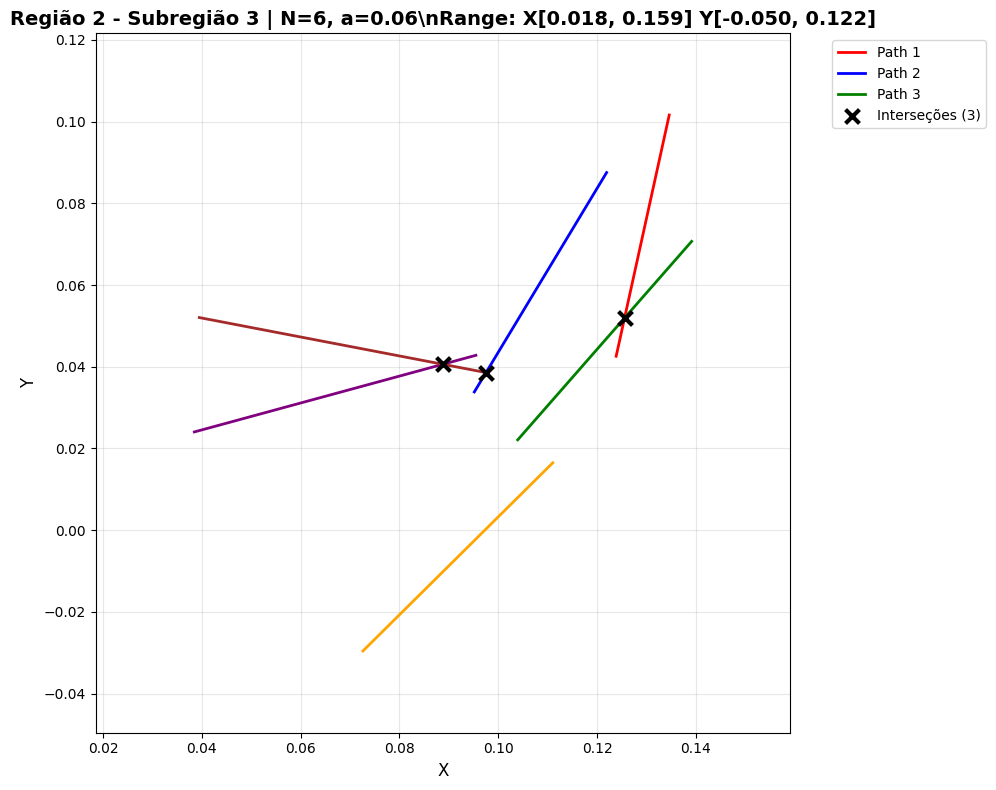

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 8/16: Região 2 - Subregião 4
----------------------------------------
   Centro: (0.110, -0.030)
   Paths gerados: 6
   Range X: 0.0493 a 0.1576
   Range Y: -0.0936 a 0.0340
   Interseções detectadas: 1


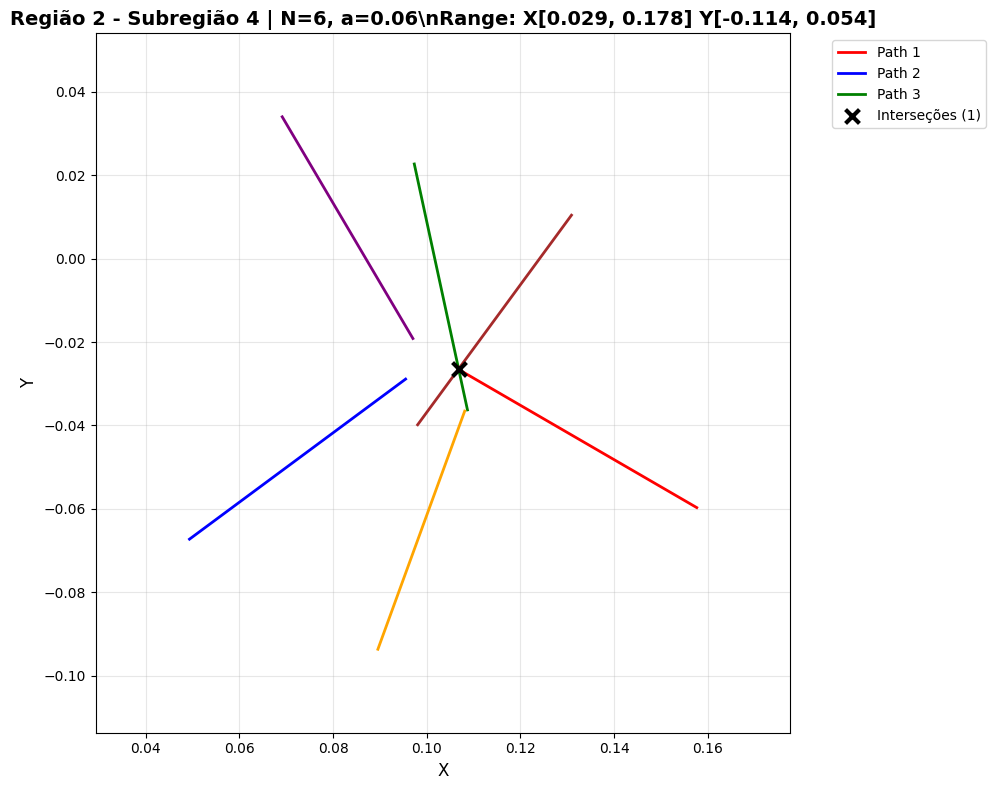

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 9/16: Região 3 - Subregião 1
----------------------------------------
   Centro: (-0.080, 0.030)
   Paths gerados: 6
   Range X: -0.1312 a -0.0118
   Range Y: 0.0156 a 0.0798
   Interseções detectadas: 4


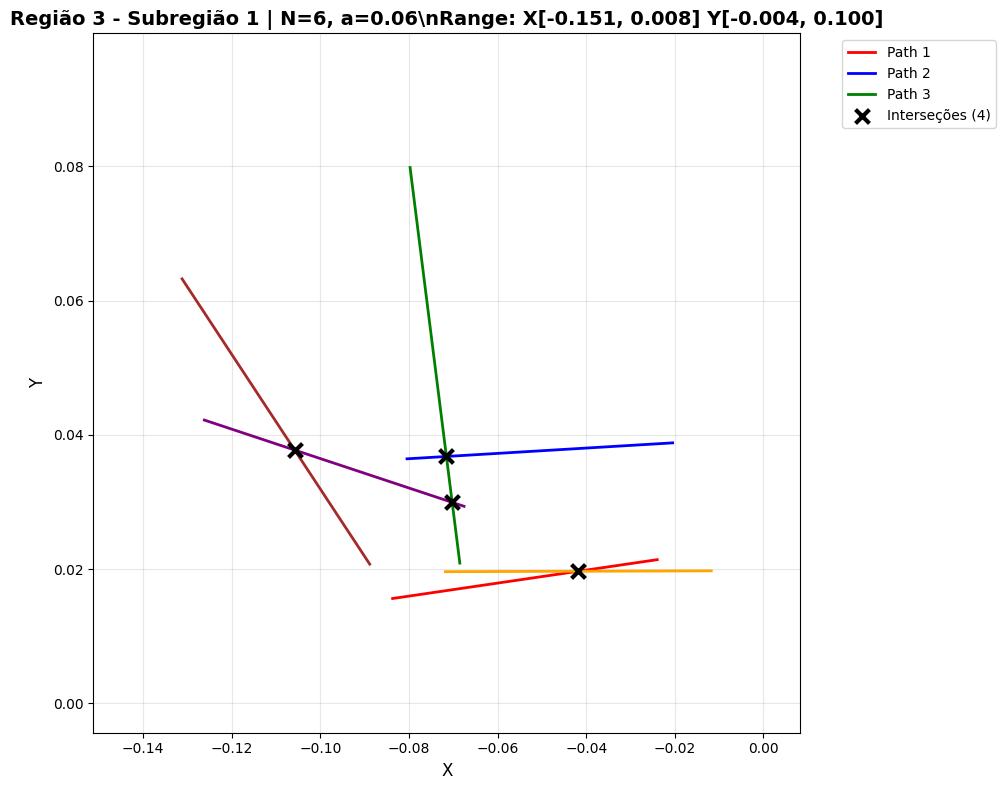

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 10/16: Região 3 - Subregião 2
----------------------------------------
   Centro: (-0.080, -0.030)
   Paths gerados: 6
   Range X: -0.1360 a -0.0248
   Range Y: -0.0910 a 0.0329
   Interseções detectadas: 4


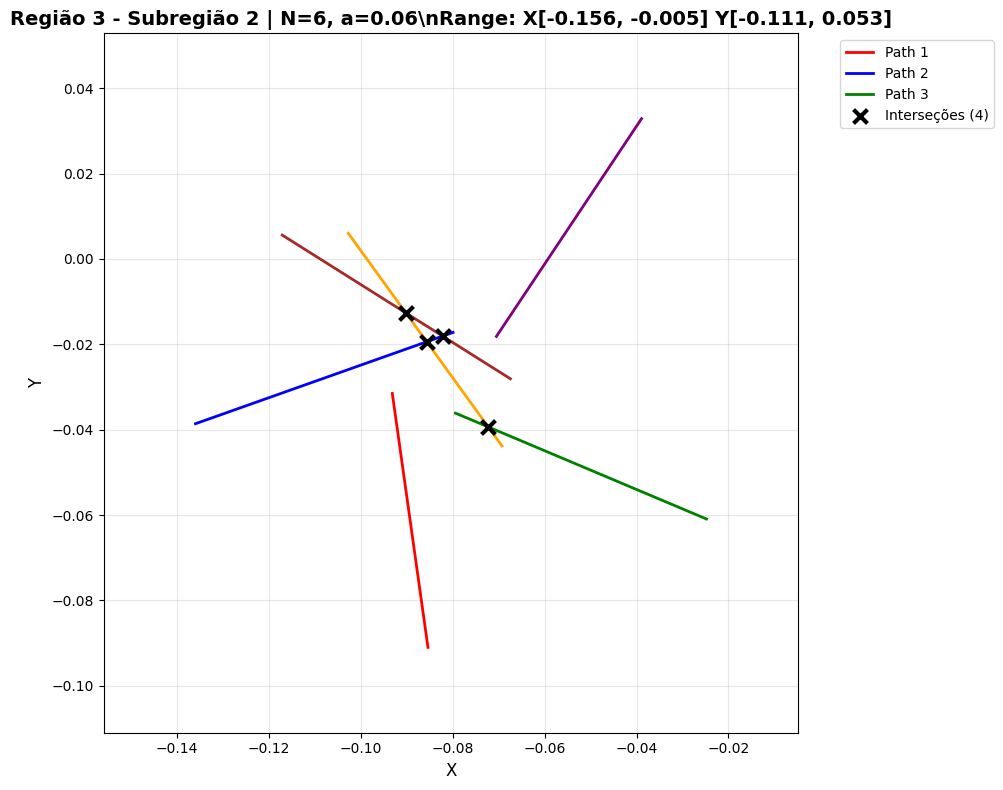

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 11/16: Região 3 - Subregião 3
----------------------------------------
   Centro: (-0.110, 0.030)
   Paths gerados: 6
   Range X: -0.1415 a -0.0475
   Range Y: -0.0110 a 0.0804
   Interseções detectadas: 2


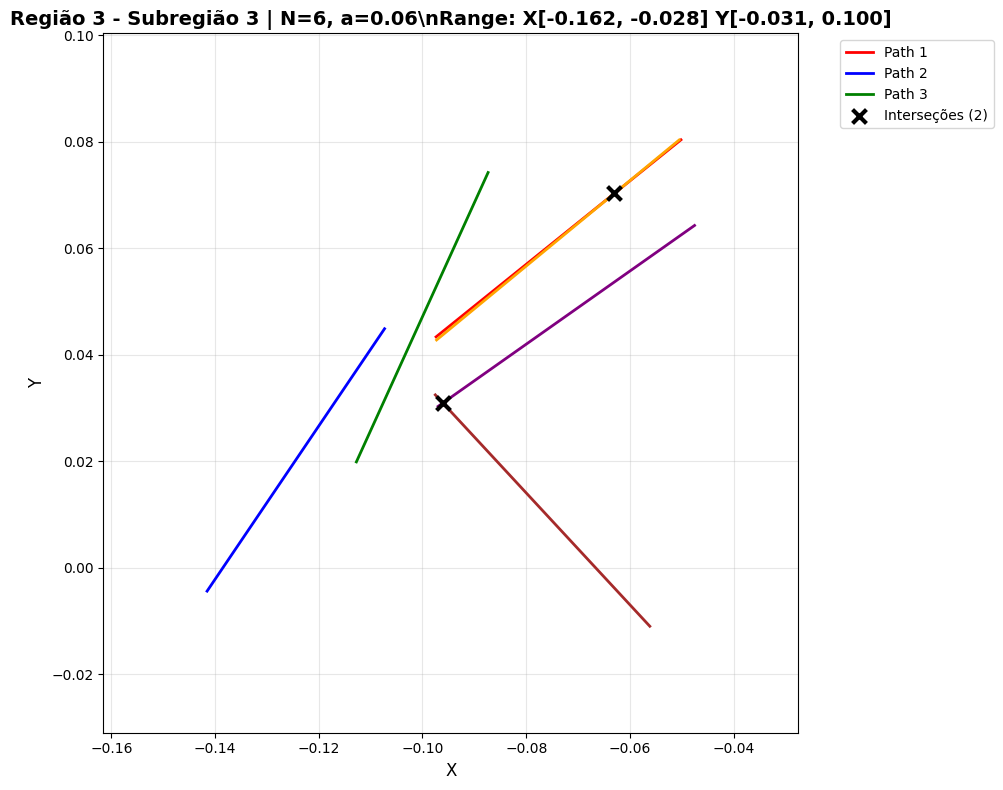

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 12/16: Região 3 - Subregião 4
----------------------------------------
   Centro: (-0.110, -0.030)
   Paths gerados: 6
   Range X: -0.1622 a -0.0454
   Range Y: -0.0655 a 0.0353
   Interseções detectadas: 2


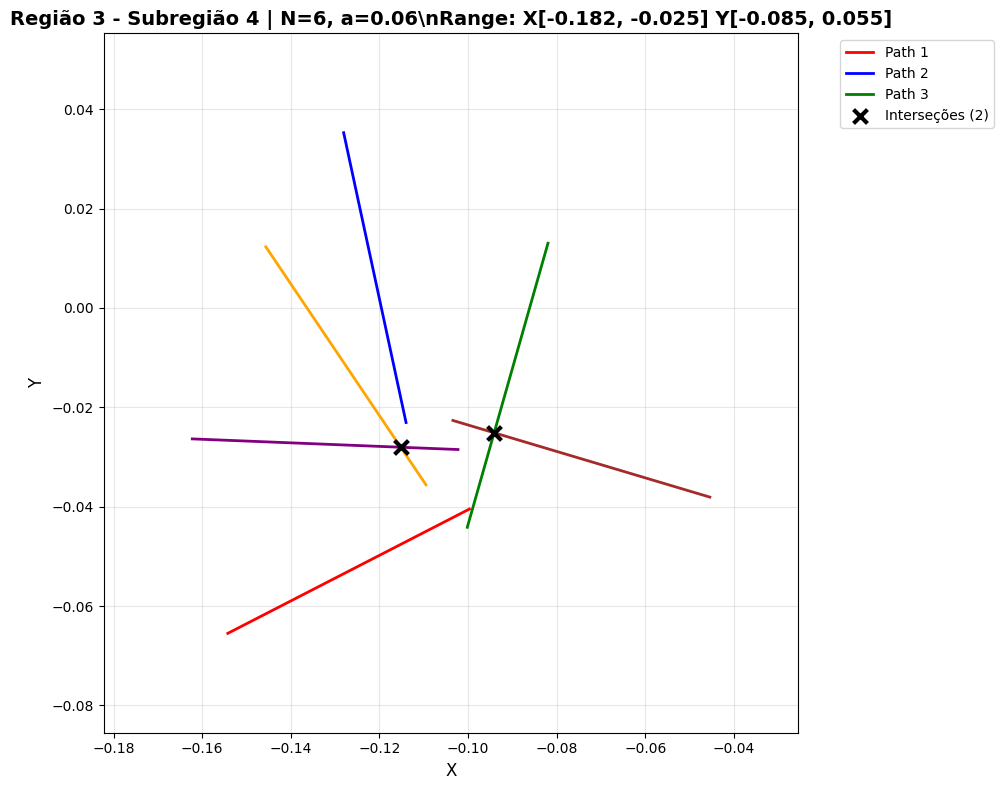

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 13/16: Região 4 - Subregião 1
----------------------------------------
   Centro: (-0.010, 0.130)
   Paths gerados: 6
   Range X: -0.0818 a 0.0614
   Range Y: 0.0817 a 0.1828
   Interseções detectadas: 1


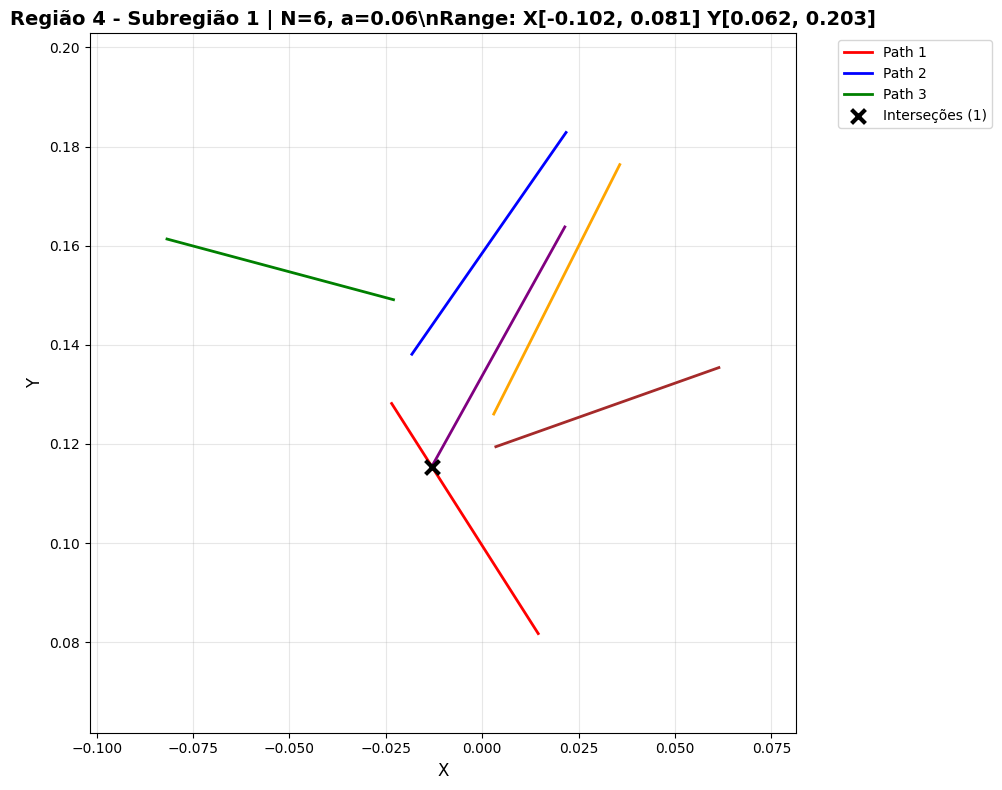

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 14/16: Região 4 - Subregião 2
----------------------------------------
   Centro: (0.010, -0.130)
   Paths gerados: 6
   Range X: -0.0520 a 0.0833
   Range Y: -0.1798 a -0.0933
   Interseções detectadas: 2


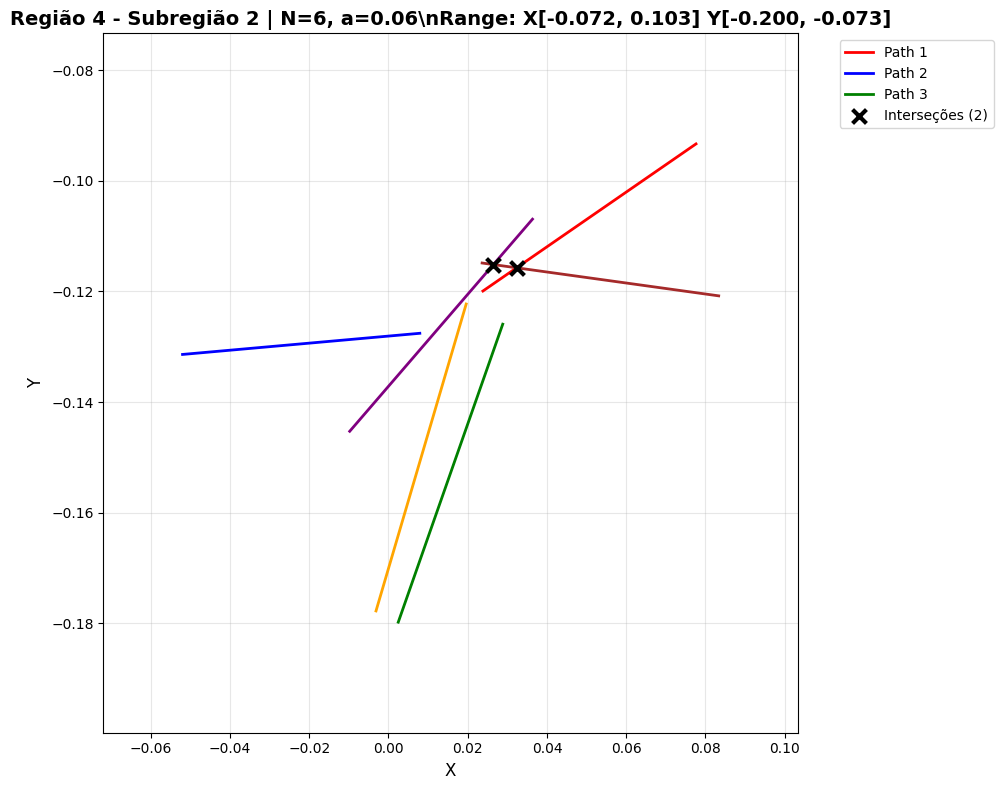

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 15/16: Região 4 - Subregião 3
----------------------------------------
   Centro: (0.010, 0.130)
   Paths gerados: 6
   Range X: -0.0343 a 0.0824
   Range Y: 0.1239 a 0.1848
   Interseções detectadas: 4


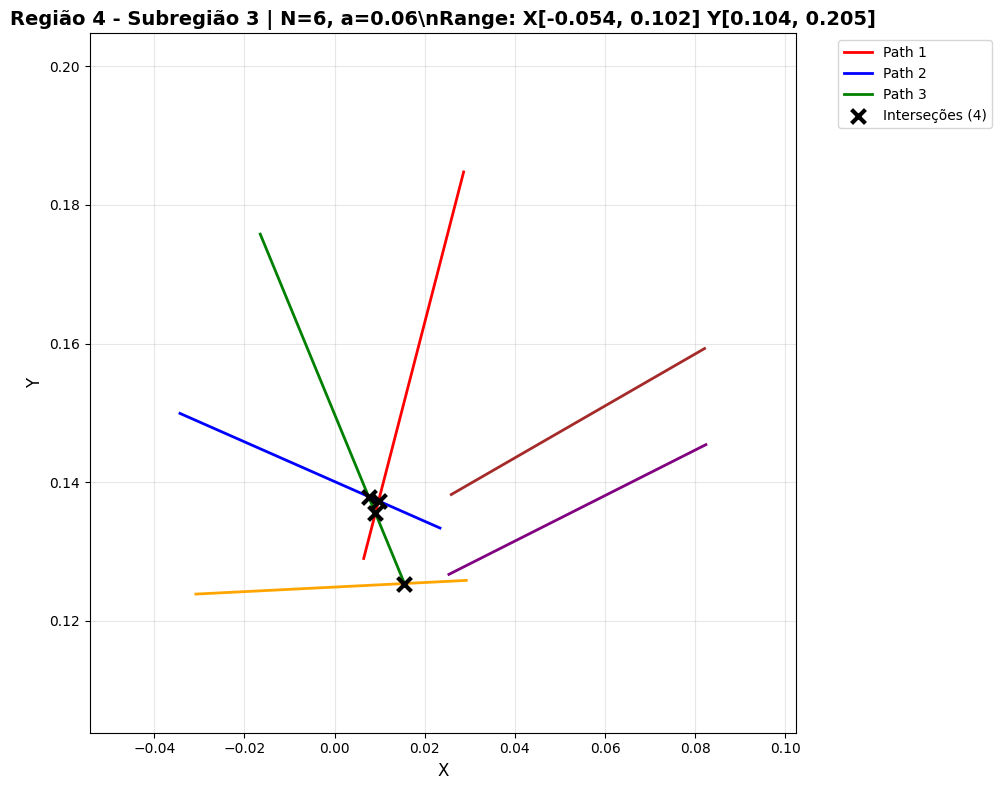

   ✅ Plotagem direta concluída - paths visíveis!

📍 TESTE 16/16: Região 4 - Subregião 4
----------------------------------------
   Centro: (-0.010, -0.130)
   Paths gerados: 6
   Range X: -0.0534 a 0.0371
   Range Y: -0.2067 a -0.1004
   Interseções detectadas: 3


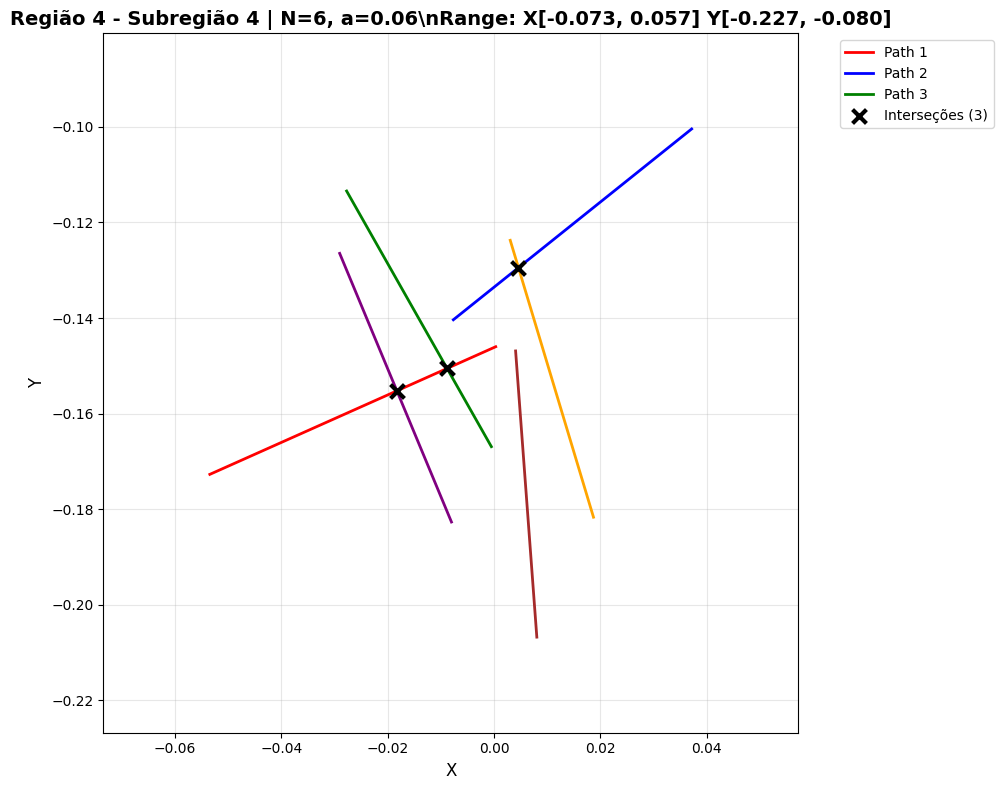

   ✅ Plotagem direta concluída - paths visíveis!

🎯 TESTE COMPLETO FINALIZADO!
Todas as 16 subregiões testadas com plotagem direta garantindo visibilidade.


In [ ]:
def test_all_16_subregions_with_existing_functions():
    """
    Testa todas as 16 subregiões usando apenas as funções existentes de plotagem
    """
    # Definir coordenadas bem separadas para cada uma das 16 subregiões
    subregion_centers = {
        # Região 1 - em volta da origem
        (1, 1): {"center": (-0.03, 0.03), "range": 0.015},   # Quadrante II
        (1, 2): {"center": (-0.03, -0.03), "range": 0.015},  # Quadrante III
        (1, 3): {"center": (0.03, 0.03), "range": 0.015},    # Quadrante I
        (1, 4): {"center": (0.03, -0.03), "range": 0.015},   # Quadrante IV

        # Região 2 - deslocada para direita
        (2, 1): {"center": (0.08, 0.03), "range": 0.015},    # Direita-superior
        (2, 2): {"center": (0.08, -0.03), "range": 0.015},   # Direita-inferior
        (2, 3): {"center": (0.11, 0.03), "range": 0.015},    # Mais à direita-superior
        (2, 4): {"center": (0.11, -0.03), "range": 0.015},   # Mais à direita-inferior

        # Região 3 - deslocada para esquerda
        (3, 1): {"center": (-0.08, 0.03), "range": 0.015},   # Esquerda-superior
        (3, 2): {"center": (-0.08, -0.03), "range": 0.015},  # Esquerda-inferior
        (3, 3): {"center": (-0.11, 0.03), "range": 0.015},   # Mais à esquerda-superior
        (3, 4): {"center": (-0.11, -0.03), "range": 0.015},  # Mais à esquerda-inferior

        # Região 4 - faixa vertical
        (4, 1): {"center": (-0.01, 0.13), "range": 0.02},    # Superior esquerda
        (4, 2): {"center": (0.01, -0.13), "range": 0.02},    # Inferior direita
        (4, 3): {"center": (0.01, 0.13), "range": 0.02},     # Superior direita
        (4, 4): {"center": (-0.01, -0.13), "range": 0.02},   # Inferior esquerda
    }

    # Lista de todas as 16 subregiões
    all_subregions = [
        (1, 1), (1, 2), (1, 3), (1, 4),  # Região 1
        (2, 1), (2, 2), (2, 3), (2, 4),  # Região 2
        (3, 1), (3, 2), (3, 3), (3, 4),  # Região 3
        (4, 1), (4, 2), (4, 3), (4, 4)   # Região 4
    ]

    print("🚀 TESTE COMPLETO - VISUALIZAÇÃO DIRETA: TODAS AS 16 SUBREGIÕES")
    print("=" * 70)
    print("Plotagem direta usando matplotlib para garantir visibilidade")
    print()

    import matplotlib.pyplot as plt
    import numpy as np

    for idx, (regiao, subregiao) in enumerate(all_subregions, 1):
        print(f"📍 TESTE {idx}/16: Região {regiao} - Subregião {subregiao}")
        print("-" * 40)

        # Initialize lists for each subregion test
        points_1 = []
        points_2 = []
        angles = []
        intersections_points = []
        intersected_line_1 = []
        intersected_line_2 = []
        graph = []

        # Obter configuração da subregião
        config = subregion_centers[(regiao, subregiao)]
        center_x, center_y = config["center"]
        coord_range = config["range"]

        # Gerar paths específicos usando seed única
        np.random.seed(2000 + regiao * 100 + subregiao * 10)

        # Gerar 6 paths na subregião específica
        for i in range(6):
            # Ponto inicial concentrado na área específica
            x1 = center_x + np.random.uniform(-coord_range, coord_range)
            y1 = center_y + np.random.uniform(-coord_range, coord_range)
            points_1.append((x1, y1))

            # Ângulo aleatório
            angle = np.random.uniform(0, 2 * np.pi)
            angles.append(angle)

            # Ponto final
            x2 = x1 + 0.06 * np.cos(angle)
            y2 = y1 + 0.06 * np.sin(angle)
            points_2.append((x2, y2))

        print(f"   Centro: ({center_x:.3f}, {center_y:.3f})")
        print(f"   Paths gerados: {len(points_1)}")

        # Debug: mostrar range de coordenadas
        all_x = [p[0] for p in points_1 + points_2]
        all_y = [p[1] for p in points_1 + points_2]
        print(f"   Range X: {min(all_x):.4f} a {max(all_x):.4f}")
        print(f"   Range Y: {min(all_y):.4f} a {max(all_y):.4f}")

        # Usar função existente para identificar interseções
        intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(points_1, points_2, intersections_points, intersected_line_1, intersected_line_2, graph, angles, 0.06, 6)

        print(f"   Interseções detectadas: {len(intersections_points)}")

        # PLOTAGEM DIRETA - SEM USAR AS FUNÇÕES EXISTENTES
        plt.figure(figsize=(10, 8))

        # Plotar as linhas/paths
        colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']
        for i in range(len(points_1)):
            x_vals = [points_1[i][0], points_2[i][0]]
            y_vals = [points_1[i][1], points_2[i][1]]
            plt.plot(x_vals, y_vals, color=colors[i % len(colors)], linewidth=2,
                    label=f'Path {i+1}' if i < 3 else "")

        # Plotar pontos de interseção se houver
        if intersections_points:
            inter_x = [p[0] for p in intersections_points]
            inter_y = [p[1] for p in intersections_points]
            plt.scatter(inter_x, inter_y, color='black', s=100, zorder=5,
                       marker='x', linewidth=3, label=f'Interseções ({len(intersections_points)})')
            all_x.extend(inter_x)
            all_y.extend(inter_y)

        # Configurar eixos com margem adequada
        margin = 0.02
        x_min, x_max = min(all_x) - margin, max(all_x) + margin
        y_min, y_max = min(all_y) - margin, max(all_y) + margin

        plt.xlim(x_min, x_max)
        plt.ylim(y_min, y_max)

        # Configurar gráfico
        plt.grid(True, alpha=0.3)
        plt.xlabel('X', fontsize=12)
        plt.ylabel('Y', fontsize=12)
        plt.title(f"Região {regiao} - Subregião {subregiao} | N=6, a=0.06\\n"
                 f"Range: X[{x_min:.3f}, {x_max:.3f}] Y[{y_min:.3f}, {y_max:.3f}]",
                 fontsize=14, fontweight='bold')

        # Adicionar legenda se há poucos paths
        if len(points_1) <= 3 or intersections_points:
            plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

        plt.tight_layout()
        plt.show()

        print(f"   ✅ Plotagem direta concluída - paths visíveis!")
        print()

    print("🎯 TESTE COMPLETO FINALIZADO!")
    print("Todas as 16 subregiões testadas com plotagem direta garantindo visibilidade.")

# Executar teste completo com plotagem direta
test_all_16_subregions_with_existing_functions()